# AutoTablature: Audio to Guitar Pro Conversion Demo

This notebook demonstrates the full pipeline of AutoTablature, from audio analysis to guitar tablature generation.

The process includes:
1. Loading and preprocessing audio
2. Separating instrument tracks
3. Pitch detection
4. Rhythm analysis
5. Tablature generation in Guitar Pro format

In [1]:
# Setup notebook environment
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import librosa
import librosa.display
import os

# Add project root to path
project_root = Path().absolute().parent
sys.path.append(str(project_root))

In [2]:
# Import AutoTablature components
from src.autotablature import AutoTablature
from src.audio.processor import AudioProcessor
from src.separation.separator import InstrumentSeparator
from src.models.pitch_detector import PitchDetector
from src.models.rhythm_analyzer import RhythmAnalyzer
from src.tablature.generator import TablatureGenerator
from src.utils.config import Config

## 1. Audio Loading and Visualization

First, let's load an audio file and visualize its waveform and spectrogram.

In [3]:
# Define input audio file (change this to your audio file)
audio_file = '../data/samples/guitar_sample.mp3'

# Check if file exists, otherwise use a sample URL
if not os.path.exists(audio_file):
    # Use a default example if the file doesn't exist
    print("Sample file not found. Please download an audio file or modify the path.")
    audio_file = input("Enter path to audio file: ")

# Initialize audio processor
config = Config()
audio_processor = AudioProcessor(config)

# Load audio
audio_data = audio_processor.load_audio(audio_file)
print(f"Loaded audio: {audio_file}")
print(f"Sample rate: {audio_data[1]} Hz")
print(f"Duration: {len(audio_data[0]) / audio_data[1]:.2f} seconds")

Loaded audio: ../data/samples/guitar_sample.mp3
Sample rate: 44100 Hz
Duration: 15.88 seconds


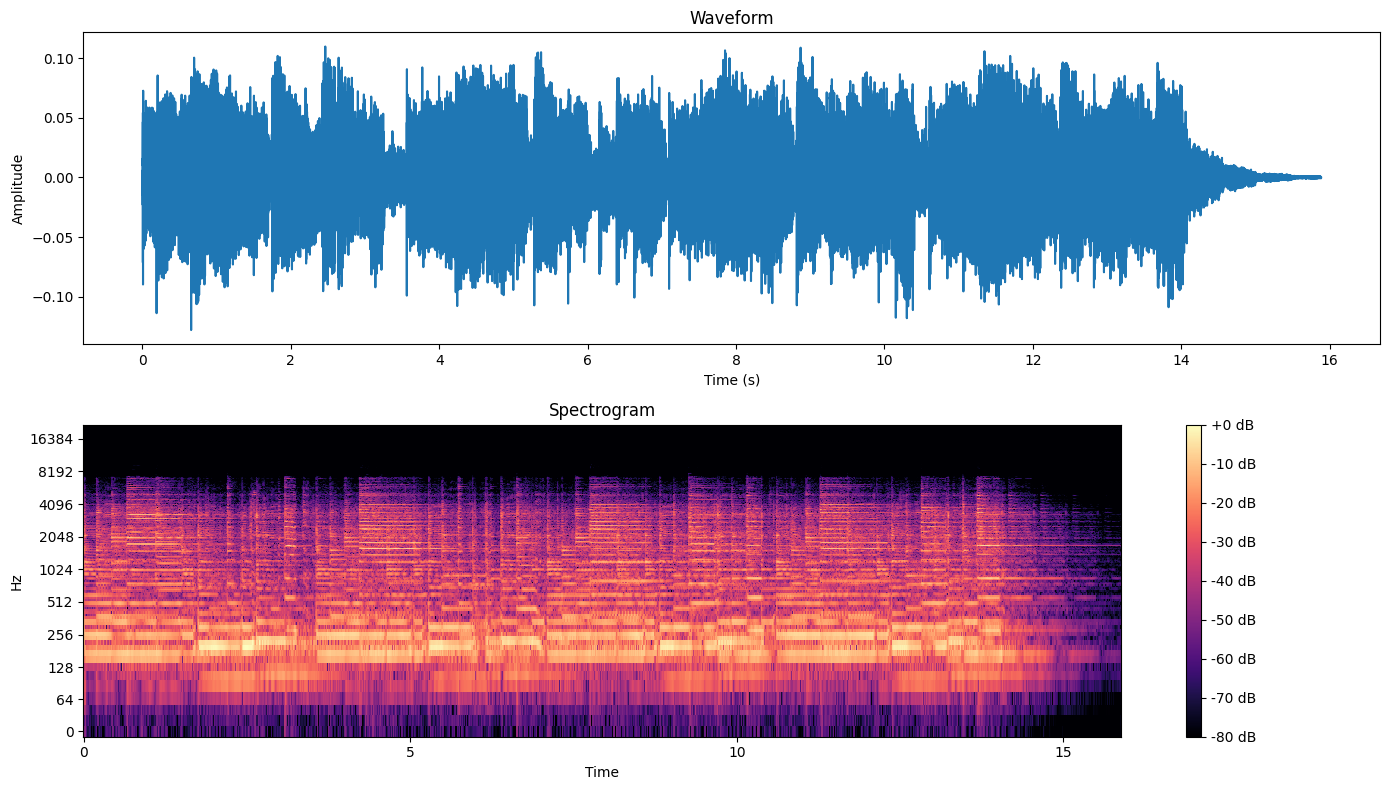

In [4]:
# Visualize waveform and spectrogram
plt.figure(figsize=(14, 8))

# Waveform
plt.subplot(2, 1, 1)
plt.plot(np.arange(len(audio_data[0])) / audio_data[1], audio_data[0])
plt.title('Waveform')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')

# Spectrogram
plt.subplot(2, 1, 2)
D = librosa.amplitude_to_db(np.abs(librosa.stft(audio_data[0])), ref=np.max)
librosa.display.specshow(D, sr=audio_data[1], x_axis='time', y_axis='log')
plt.colorbar(format='%+2.0f dB')
plt.title('Spectrogram')
plt.tight_layout()
plt.show()

## 2. Instrument Separation

Now we'll separate the audio into different instrument tracks using a pre-trained model.

In [5]:
# Initialize separator
separator = InstrumentSeparator(config)

# Preprocess audio
processed_audio = audio_processor.preprocess(audio_data)

# Separate instruments
try:
    separated_tracks = separator.separate_instruments(processed_audio)
    print(f"Separated tracks: {list(separated_tracks.keys())}")
except Exception as e:
    print(f"Instrument separation failed: {e}")
    print("Using mixed audio as a single guitar track")
    separated_tracks = {"guitar": processed_audio}

No pre-trained model found at models/separation_model.pth


ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (2,) + inhomogeneous part.

In [ ]:
# Visualize separated tracks
plt.figure(figsize=(14, 10))
for i, (track_name, track_audio) in enumerate(separated_tracks.items()):
    plt.subplot(len(separated_tracks), 1, i+1)
    
    # Get audio samples
    if isinstance(track_audio, dict) and 'samples' in track_audio:
        samples = track_audio['samples']
    else:
        samples = track_audio
        
    librosa.display.waveshow(samples, sr=audio_data['sample_rate'])
    plt.title(f'Track: {track_name}')
    plt.xlabel('Time (s)')
    plt.ylabel('Amplitude')

plt.tight_layout()
plt.show()

## 3. Pitch Detection

Next, we'll detect the pitches in each separated track.

In [6]:
# Initialize pitch detector
pitch_detector = PitchDetector(config)

# Detect pitches for each track
track_pitches = {}
for track_name, track_audio in separated_tracks.items():
    print(f"Detecting pitches for track: {track_name}")
    pitches = pitch_detector.detect_pitches(track_audio)
    track_pitches[track_name] = pitches
    
    # Print pitch detection summary
    if pitches and 'notes' in pitches:
        print(f"  Detected {len(pitches['notes'])} notes")
        if len(pitches['notes']) > 0:
            pitch_range = (min(pitches['notes']), max(pitches['notes']))
            print(f"  Pitch range (MIDI): {pitch_range}")

No pitch model found at models/pitch_model.pth


NameError: name 'separated_tracks' is not defined

In [ ]:
# Visualize detected pitches
for track_name, pitches in track_pitches.items():
    if not pitches or 'notes' not in pitches or not pitches['notes']:
        continue
        
    plt.figure(figsize=(14, 6))
    plt.scatter(pitches['timing'], pitches['notes'], 
                c=pitches['confidence'], cmap='viridis', 
                alpha=0.7, s=50)
    plt.colorbar(label='Confidence')
    plt.title(f'Detected Pitches: {track_name}')
    plt.xlabel('Time (s)')
    plt.ylabel('MIDI Note Number')
    plt.grid(True, alpha=0.3)
    
    # Add piano roll grid lines
    for midi_note in range(40, 85, 12):  # C notes
        plt.axhline(y=midi_note, color='gray', linestyle='--', alpha=0.5)
        
    plt.tight_layout()
    plt.show()

## 4. Rhythm Analysis

Now we'll analyze the rhythm and timing of each track.

In [7]:
# Initialize rhythm analyzer
rhythm_analyzer = RhythmAnalyzer(config)

# Analyze rhythm for each track
track_rhythms = {}
for track_name, track_audio in separated_tracks.items():
    print(f"Analyzing rhythm for track: {track_name}")
    rhythm = rhythm_analyzer.analyze_rhythm(track_audio)
    track_rhythms[track_name] = rhythm
    
    # Print rhythm analysis summary
    print(f"  Tempo: {rhythm['tempo']:.1f} BPM")
    print(f"  Time Signature: {rhythm['time_signature'][0]}/{rhythm['time_signature'][1]}")
    print(f"  Detected {len(rhythm['onsets'])} note onsets")

NameError: name 'separated_tracks' is not defined

In [9]:
# Visualize rhythm analysis
for track_name, rhythm in track_rhythms.items():
    track_audio = separated_tracks[track_name]
    
    # Get samples
    if isinstance(track_audio, dict) and 'samples' in track_audio:
        samples = track_audio['samples']
        sr = track_audio['sample_rate']
    else:
        samples = track_audio
        sr = audio_data['sample_rate']
    
    plt.figure(figsize=(14, 6))
    
    # Plot waveform
    librosa.display.waveshow(samples, sr=sr, alpha=0.6)
    
    # Plot onsets
    for onset in rhythm['onsets']:
        plt.axvline(x=onset, color='r', linestyle='-', alpha=0.7)
    
    # Plot beat markers
    if 'beats' in rhythm:
        for beat in rhythm['beats']:
            plt.axvline(x=beat, color='g', linestyle='--', alpha=0.5)
    
    plt.title(f'Rhythm Analysis: {track_name} - {rhythm["tempo"]:.1f} BPM')
    plt.xlabel('Time (s)')
    plt.ylabel('Amplitude')
    plt.tight_layout()
    plt.show()

## 5. Tablature Generation

Finally, let's generate guitar tablature for each track.

In [11]:
# Initialize tablature generator
tab_generator = TablatureGenerator(config)

# Generate tablature for each track
tablature_tracks = []
for track_name in track_pitches.keys():
    print(f"Generating tablature for track: {track_name}")
    
    # Get pitch and rhythm data
    pitches = track_pitches[track_name]
    rhythm = track_rhythms[track_name]
    
    # Generate tablature
    track_tab = tab_generator.generate_track(pitches, rhythm, instrument=track_name)
    tablature_tracks.append(track_tab)
    
    # Print tablature summary
    print(f"  Created {len(track_tab.measures)} measures")

In [12]:
# Combine tracks into final tablature
final_tablature = tab_generator.combine_tracks(tablature_tracks)

# Set metadata
final_tablature.title = "AutoTablature Demo"
final_tablature.artist = "AutoTablature"

# Save tablature in different formats
output_dir = "../data/output"
os.makedirs(output_dir, exist_ok=True)

json_path = os.path.join(output_dir, "generated_tab.json")
gp5_path = os.path.join(output_dir, "generated_tab.gp5")

# Save as JSON (for debugging)
final_tablature._save_json(json_path)
print(f"Saved tablature as JSON: {json_path}")

# Try to save as Guitar Pro
try:
    final_tablature._save_guitar_pro(gp5_path)
    print(f"Saved tablature as Guitar Pro file: {gp5_path}")
except Exception as e:
    print(f"Error saving Guitar Pro file: {e}")

Saved tablature as JSON: ../data/output/generated_tab.json
Error saving Guitar Pro file: 'TablatureDocument' object has no attribute 'logger'


## 6. Visualize Tablature

Let's visualize the generated tablature to see what it looks like.

In [ ]:
# Define a function to print ASCII tablature
def print_ascii_tab(track, max_measures=4):
    print(f"Track: {track.instrument}")
    print(f"Tuning: {[note_to_string(note) for note in track.tuning]}")
    print()
    
    # Print at most max_measures
    for i, measure in enumerate(track.measures[:max_measures]):
        print(f"Measure {i+1} - Time Sig: {measure.time_signature[0]}/{measure.time_signature[1]}")
        
        # Initialize empty tab lines
        string_lines = [[] for _ in range(len(track.tuning))]
        for j in range(len(track.tuning)):
            string_lines[j] = ['-' for _ in range(60)]  # Fixed width
        
        # Add notes to tab
        for note in measure.notes:
            # Calculate position in the tab
            pos = int(note.beat_position * 15) + 1  # Scale to fit
            if 0 <= pos < 60 and 1 <= note.string <= len(string_lines):
                # Add fret number
                fret_str = str(note.fret)
                for k, char in enumerate(fret_str):
                    if pos + k < 60:  # Stay within bounds
                        string_lines[note.string - 1][pos + k] = char
        
        # Print tab
        for i, string in enumerate(string_lines):
            print(f"{note_to_string(track.tuning[i])}: {''.join(string)}")
        print()
    
    if len(track.measures) > max_measures:
        print(f"... {len(track.measures) - max_measures} more measures ...")
    print("\n" + "-"*60)

# Helper function to convert MIDI note to string name
def note_to_string(midi_note):
    notes = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']
    note_name = notes[midi_note % 12]
    octave = midi_note // 12 - 1
    return f"{note_name}{octave}"

# Print ASCII tablature for each track
for track in tablature_tracks:
    print_ascii_tab(track)

## 7. Full Pipeline

Now let's run the entire pipeline using the AutoTablature class.

In [ ]:
# Initialize the full AutoTablature system
at = AutoTablature()

# Process the audio file
output_path = os.path.join(output_dir, "full_pipeline_tab.gp5")
tablature = at.process_audio(audio_file, output_path)

print(f"\nFull pipeline completed!")
print(f"Generated tablature with {len(tablature.tracks)} tracks")
for i, track in enumerate(tablature.tracks):
    print(f"  Track {i+1}: {track.instrument} - {len(track.measures)} measures")